<a href="https://colab.research.google.com/github/GilbertOwen/reefscan-id/blob/stage2-training/notebooks/05_stage2_training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# ReefScan-ID: Stage 2 training

Train EfficientNet-B0 to label a patch of coral as healthy, bleached or dead. The patches are read from the files saved by notebook 04, so nothing is cut here. Run in Google Colab with a GPU runtime.

### Setup: Colab runtime and Google Drive

In [1]:
import os
import torch
from google.colab import drive

drive.mount("/content/drive")

device = "cuda" if torch.cuda.is_available() else "cpu"
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none"
print("GPU: {}".format(gpu_name))
print("CPU count: {}".format(os.cpu_count()))

base_dir = "/content/drive/MyDrive/ReefScan-ID"
data_dir = base_dir + "/Processed/stage2_patches"
print("Drive folder found: {}".format(os.path.isdir(base_dir)))
print("Patch folder found: {}".format(os.path.isdir(data_dir)))

Mounted at /content/drive
GPU: Tesla T4
CPU count: 2
Drive folder found: True
Patch folder found: True


### Setup: libraries

In [2]:
import json
import random
import time
import numpy as np
import pandas as pd
import torchvision

print("torch version: {}".format(torch.__version__))
print("torchvision version: {}".format(torchvision.__version__))
print("numpy version: {}".format(np.__version__))
print("pandas version: {}".format(pd.__version__))

torch version: 2.14.1+cu130
torchvision version: 0.29.1+cu130
numpy version: 2.4.6
pandas version: 2.2.3


### Settings

In [3]:
# Change only this value between the E3 runs
source = "coralscapes"

loader_crop = 128
patch_size = 224
batch_size = 32
num_workers = 2
epochs = 30
learning_rate = 1e-4
weight_decay = 0.01
seed = 0
timing_steps = 30

state_names = {0: "healthy", 1: "bleached", 2: "dead"}
sources_for = {"coralscapes": ["coralscapes"], "noaa": ["noaa"], "both": ["coralscapes", "noaa"]}

random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)

print("Source setting: {} -> {}".format(source, sources_for[source]))
print("Loader crop: {} px, resized to {} px".format(loader_crop, patch_size))
print("Batch size: {}, workers: {}".format(batch_size, num_workers))
print("Epochs: {}, learning rate: {}, weight decay: {}".format(epochs, learning_rate, weight_decay))

Source setting: coralscapes -> ['coralscapes']
Loader crop: 128 px, resized to 224 px
Batch size: 32, workers: 2
Epochs: 30, learning rate: 0.0001, weight decay: 0.01


**Observation**:

## Section 1: Data

Question: do the saved patches load as batches of 224 by 224 images with the right labels for the chosen source setting, and which class weights follow from the train counts?

Checks: list the saved files, build a dataset and loaders from the arrays and manifests, read one batch, time ten train batches, compute the class weights from the train counts, and compare NOAA file name prefixes across train and val. The manifests hold only train and validation rows, so no test data is read.

### Saved patch files

In [4]:
files = ["coralscapes_manifest.csv", "noaa_manifest.csv",
         "coralscapes_train_128.npy", "coralscapes_validation_128.npy",
         "noaa_train_224.npy", "noaa_validation_224.npy"]
for name in files:
    file_path = data_dir + "/" + name
    if os.path.isfile(file_path):
        print("{}: {:.1f} MB".format(name, os.path.getsize(file_path) / 1024 ** 2))
    else:
        print("{}: not found".format(name))

cs_manifest = pd.read_csv(data_dir + "/coralscapes_manifest.csv")
noaa_manifest = pd.read_csv(data_dir + "/noaa_manifest.csv")
print("Coralscapes manifest columns: {}".format(list(cs_manifest.columns)))
print("NOAA manifest columns: {}".format(list(noaa_manifest.columns)))

both = pd.concat([cs_manifest, noaa_manifest], ignore_index=True)
print("Rows per source, split and label:")
print(pd.crosstab([both["source"], both["split"]], both["label"]).to_string())

with open(data_dir + "/settings.json") as handle:
    print("Patch settings saved by notebook 04: {}".format(json.load(handle)))

coralscapes_manifest.csv: 2.5 MB
noaa_manifest.csv: 0.6 MB
coralscapes_train_128.npy: 1043.1 MB
coralscapes_validation_128.npy: 108.8 MB
noaa_train_224.npy: 1046.8 MB
noaa_validation_224.npy: 224.2 MB
Coralscapes manifest columns: ['source', 'split', 'photo_id', 'photo', 'row', 'y', 'x', 'label', 'state', 'purity_128', 'coverage_128', 'purity_256', 'coverage_256']
NOAA manifest columns: ['source', 'split', 'photo_id', 'label', 'state', 'row']
Rows per source, split and label:
label                   bleached  dead  healthy
source      split                              
coralscapes train            840  3353    18060
            validation       106   777     1437
noaa        train           2751     0     4541
            validation       589     0      973
Patch settings saved by notebook 04: {'grid_cell': 128, 'margin': 128, 'grid_seed': 0, 'cap_per_state_per_photo': 20, 'cap_seed': 0, 'purity_threshold': 0.7, 'purity_threshold_crop': 128, 'crop_sizes_saved': [128, 256], 'state_name

### Patch dataset class

In [5]:
import torch.nn.functional as F
from torch.utils.data import ConcatDataset, DataLoader, Dataset

source_ids = {"coralscapes": 0, "noaa": 1}


class PatchDataset(Dataset):
    def __init__(self, source_name, split):
        manifest = cs_manifest if source_name == "coralscapes" else noaa_manifest
        table = manifest[manifest["split"] == split]
        self.table = table.reset_index(drop=True)
        self.rows = self.table["row"].to_numpy()
        self.states = self.table["state"].to_numpy()
        self.source_id = source_ids[source_name]
        if source_name == "coralscapes":
            self.array_path = "{}/coralscapes_{}_{}.npy".format(data_dir, split, loader_crop)
        else:
            self.array_path = "{}/noaa_{}_{}.npy".format(data_dir, split, patch_size)
        self.patches = None

    def __len__(self):
        return len(self.table)

    def __getitem__(self, index):
        # The array file is opened on first use
        if self.patches is None:
            self.patches = np.load(self.array_path, mmap_mode="r")
        patch = torch.from_numpy(np.array(self.patches[self.rows[index]]))
        image = patch.permute(2, 0, 1).float().div(255)
        if image.shape[-1] != patch_size:
            image = F.interpolate(image.unsqueeze(0), size=(patch_size, patch_size),
                                  mode="bilinear", align_corners=False).squeeze(0)
        return image, int(self.states[index]), self.source_id


print("Dataset class defined, patches resized to {} px".format(patch_size))

Dataset class defined, patches resized to 224 px


### Loaders

In [6]:
train_sets = [PatchDataset(name, "train") for name in sources_for[source]]
train_data = ConcatDataset(train_sets)
train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True, num_workers=num_workers)

# Both validation sets are always loaded, so every run reports each source
val_loaders = {}
for name in source_ids:
    val_loaders[name] = DataLoader(PatchDataset(name, "validation"), batch_size=batch_size,
                                   shuffle=False, num_workers=num_workers)

train_table = pd.concat([data.table for data in train_sets], ignore_index=True)
print("Train rows: {}, batches per epoch: {}".format(len(train_data), len(train_loader)))
print("Train labels: {}".format(train_table["label"].value_counts().to_dict()))
for name, loader in val_loaders.items():
    print("Validation {}: {} rows, {} batches, labels {}".format(
        name, len(loader.dataset), len(loader), loader.dataset.table["label"].value_counts().to_dict()))

Train rows: 22253, batches per epoch: 696
Train labels: {'healthy': 18060, 'dead': 3353, 'bleached': 840}
Validation coralscapes: 2320 rows, 73 batches, labels {'healthy': 1437, 'dead': 777, 'bleached': 106}
Validation noaa: 1562 rows, 49 batches, labels {'healthy': 973, 'bleached': 589}


### One batch check

In [7]:
images, labels, batch_sources = next(iter(train_loader))
print("Train batch: images {}, dtype {}, min {:.3f}, max {:.3f}".format(
    tuple(images.shape), images.dtype, images.min().item(), images.max().item()))
print("Train batch: labels {}, sources {}".format(
    sorted(set(labels.tolist())), sorted(set(batch_sources.tolist()))))

# Validation is not shuffled, so its first batch is not representative
for name, loader in val_loaders.items():
    images, labels, batch_sources = next(iter(loader))
    print("Validation {}, first batch: images {}, labels {}".format(
        name, tuple(images.shape), sorted(set(labels.tolist()))))

start = time.time()
steps = 0
for batch in train_loader:
    steps += 1
    if steps == 10:
        break
print("Reading {} train batches took {:.1f} seconds".format(steps, time.time() - start))

Train batch: images (32, 3, 224, 224), dtype torch.float32, min 0.000, max 1.000
Train batch: labels [0, 2], sources [0]
Validation coralscapes, first batch: images (32, 3, 224, 224), labels [0, 1, 2]
Validation noaa, first batch: images (32, 3, 224, 224), labels [0]
Reading 10 train batches took 6.5 seconds


### Class weights

In [8]:
counts = train_table["state"].value_counts().reindex(list(state_names), fill_value=0)

# Inverse frequency over the classes that have train rows, scaled to mean 1
inverse = 1 / counts.where(counts > 0)
class_weights = (inverse / inverse.mean()).fillna(0.0)

for class_id, class_name in state_names.items():
    print("{}: {} train rows, {:.1f}% of rows, weight {:.3f}".format(
        class_name, counts[class_id], 100 * counts[class_id] / counts.sum(), class_weights[class_id]))

weight_tensor = torch.tensor(class_weights.to_numpy(), dtype=torch.float32, device=device)

healthy: 18060 train rows, 81.2% of rows, weight 0.108
bleached: 840 train rows, 3.8% of rows, weight 2.313
dead: 3353 train rows, 15.1% of rows, weight 0.579


### NOAA file name prefixes across train and val

The meaning of the parts of a NOAA file name is not documented here, so two prefix lengths are compared.

In [9]:
stems = noaa_manifest["photo_id"].str.split("/").str[-1].str.rsplit(".", n=1).str[0]
parts = stems.str.split("_")
noaa_groups = pd.DataFrame({
    "split": noaa_manifest["split"],
    "first_two": parts.str[:2].str.join("_"),
    "first_three": parts.str[:3].str.join("_"),
})

for column in ["first_two", "first_three"]:
    splits_per_group = noaa_groups.groupby(column)["split"].nunique()
    shared = splits_per_group[splits_per_group > 1].index
    val_rows = noaa_groups[noaa_groups["split"] == "validation"]
    in_shared = val_rows[column].isin(shared).sum()
    print("{}: {} groups, {} appear in both train and val".format(column, len(splits_per_group), len(shared)))
    print("{}: {} of {} val rows are in a group that also has train rows".format(column, in_shared, len(val_rows)))
    print("{}: examples of shared groups: {}".format(column, list(shared[:5])))

first_two: 360 groups, 202 appear in both train and val
first_two: 1543 of 1562 val rows are in a group that also has train rows
first_two: examples of shared groups: ['FFS-B009_2019', 'FFS-B012_2019', 'FFS-B013_2019', 'FFS-B014_2019', 'FFS-B015_2019']
first_three: 2868 groups, 723 appear in both train and val
first_three: 1272 of 1562 val rows are in a group that also has train rows
first_three: examples of shared groups: ['FFS-B013_2019_20', 'FFS-B013_2019_21', 'FFS-B013_2019_24', 'FFS-B013_2019_27', 'FFS-B013_2019_29']


**Observation**:

## Section 2: Model and timing

Question: does EfficientNet-B0 load from the pretrained weights with three outputs and run on one batch, and how long does one training step take on this GPU?

Checks: load the model and print the transforms that come with the weights, replace the last layer, count the parameters, run one forward pass, then time 30 training steps with data loading and the model step measured separately.

### Load EfficientNet-B0

In [10]:
from torch import nn
from torchvision.models import EfficientNet_B0_Weights, efficientnet_b0

weights = EfficientNet_B0_Weights.IMAGENET1K_V1
model = efficientnet_b0(weights=weights)
model.classifier[1] = nn.Linear(model.classifier[1].in_features, len(state_names))
model = model.to(device)

transforms = weights.transforms()
image_mean = torch.tensor(transforms.mean, device=device).view(1, 3, 1, 1)
image_std = torch.tensor(transforms.std, device=device).view(1, 3, 1, 1)


def normalise(images):
    return (images - image_mean) / image_std


total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Weights: {}".format(weights))
print("Transforms that come with the weights: {}".format(transforms))
print("Mean {}, std {}".format(transforms.mean, transforms.std))
print("Last layer: {}".format(model.classifier[1]))
print("Parameters: {} total, {} trainable".format(total_params, trainable_params))

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


100%|██████████| 20.5M/20.5M [00:00<00:00, 124MB/s] 


Weights: EfficientNet_B0_Weights.IMAGENET1K_V1
Transforms that come with the weights: ImageClassification(
    crop_size=[224]
    resize_size=[256]
    mean=[0.485, 0.456, 0.406]
    std=[0.229, 0.224, 0.225]
    interpolation=InterpolationMode.BICUBIC
)
Mean [0.485, 0.456, 0.406], std [0.229, 0.224, 0.225]
Last layer: Linear(in_features=1280, out_features=3, bias=True)
Parameters: 4011391 total, 4011391 trainable


### One forward pass

In [11]:
images, labels, batch_sources = next(iter(train_loader))

model.eval()
with torch.no_grad():
    logits = model(normalise(images.to(device)))

print("Input shape: {}".format(tuple(images.shape)))
print("Logits shape: {}".format(tuple(logits.shape)))
print("Predicted labels in the batch (healthy, bleached, dead): {}".format(
    torch.bincount(logits.argmax(dim=1).cpu(), minlength=len(state_names)).tolist()))

Input shape: (32, 3, 224, 224)
Logits shape: (32, 3)
Predicted labels in the batch (healthy, bleached, dead): [5, 21, 6]


### Step timing

In [12]:
import copy

timing_model = copy.deepcopy(model)
timing_model.train()
timing_optimizer = torch.optim.AdamW(timing_model.parameters(), lr=learning_rate, weight_decay=weight_decay)

data_seconds = []
step_seconds = []
batches = iter(train_loader)
for _ in range(timing_steps):
    start = time.time()
    images, labels, batch_sources = next(batches)
    data_seconds.append(time.time() - start)

    start = time.time()
    logits = timing_model(normalise(images.to(device)))
    loss = F.cross_entropy(logits, labels.to(device), weight=weight_tensor)
    timing_optimizer.zero_grad()
    loss.backward()
    timing_optimizer.step()
    if device == "cuda":
        torch.cuda.synchronize()
    step_seconds.append(time.time() - start)

print("Steps timed: {}, batch size: {}".format(timing_steps, batch_size))
print("Step 1, includes start-up: data loading {:.2f} seconds, model step {:.2f} seconds".format(
    data_seconds[0], step_seconds[0]))
print("Steps 2 to {}: data loading {:.2f} seconds per step".format(timing_steps, np.mean(data_seconds[1:])))
print("Steps 2 to {}: model step {:.2f} seconds per step".format(timing_steps, np.mean(step_seconds[1:])))
print("Steps 2 to {}: total {:.2f} seconds per step".format(
    timing_steps, np.mean(data_seconds[1:]) + np.mean(step_seconds[1:])))

Steps timed: 30, batch size: 32
Step 1, includes start-up: data loading 0.15 seconds, model step 0.68 seconds
Steps 2 to 30: data loading 0.02 seconds per step
Steps 2 to 30: model step 0.16 seconds per step
Steps 2 to 30: total 0.18 seconds per step


**Observation**:

## Section 3: Training

Question: how do the validation macro-F1 and the per-class recall of the chosen source setting change over the epochs, and which epoch is best?

Checks: score the model before training, train with weighted cross-entropy and AdamW with a checkpoint after every epoch, score each source's validation set after every epoch, then plot the curves and show the confusion matrices of the best epoch. Only the train and validation splits are used.

### Loss, optimiser and schedule

In [13]:
def loss_fn(logits, labels):
    return F.cross_entropy(logits, labels, weight=weight_tensor)


optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
total_steps = epochs * len(train_loader)
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lambda step: max(0.0, 1 - step / total_steps))

print("Loss: cross-entropy with class weights {}".format(class_weights.round(3).tolist()))
print("Optimiser: AdamW, learning rate {}, weight decay {}".format(learning_rate, weight_decay))
print("Schedule: linear decay to 0 over {} epochs, {} steps".format(epochs, total_steps))

Loss: cross-entropy with class weights [0.108, 2.313, 0.579]
Optimiser: AdamW, learning rate 0.0001, weight decay 0.01
Schedule: linear decay to 0 over 30 epochs, 20880 steps


### Validation metrics

In [14]:
class_ids = list(state_names)


def evaluate(loader):
    confusion = np.zeros((len(class_ids), len(class_ids)), dtype=np.int64)
    model.eval()
    with torch.no_grad():
        for images, labels, batch_sources in loader:
            logits = model(normalise(images.to(device)))
            predicted = logits.argmax(dim=1).cpu().numpy()
            np.add.at(confusion, (labels.numpy(), predicted), 1)
    return confusion


def scores(confusion):
    true_count = confusion.sum(axis=1)
    predicted_count = confusion.sum(axis=0)
    correct = np.diag(confusion)
    present = true_count > 0
    recall = correct / np.maximum(true_count, 1)
    precision = correct / np.maximum(predicted_count, 1)
    f1 = 2 * precision * recall / np.maximum(precision + recall, 1e-12)
    return recall, f1, present, float(f1[present].mean())


def describe(name, confusion):
    recall, f1, present, macro_f1 = scores(confusion)
    parts = []
    for class_id, class_name in state_names.items():
        value = "{:.3f}".format(recall[class_id]) if present[class_id] else "n/a"
        parts.append("{} {}".format(class_name, value))
    print("{}: macro-F1 {:.4f} over {} classes present, recall: {}".format(
        name, macro_f1, present.sum(), ", ".join(parts)))


def evaluate_all():
    confusions = {name: evaluate(loader) for name, loader in val_loaders.items()}
    own_confusion = sum(confusions[name] for name in sources_for[source])
    return confusions, own_confusion


start = time.time()
confusions, own_confusion = evaluate_all()
print("Model before training (pretrained body, new last layer)")
for name, confusion in confusions.items():
    describe("Validation " + name, confusion)
describe("Validation for the source setting '{}'".format(source), own_confusion)
print("One validation pass over both sets took {:.1f} seconds".format(time.time() - start))

Model before training (pretrained body, new last layer)
Validation coralscapes: macro-F1 0.1341 over 3 classes present, recall: healthy 0.106, bleached 0.585, dead 0.118
Validation noaa: macro-F1 0.3613 over 2 classes present, recall: healthy 0.147, bleached 0.722, dead n/a
Validation for the source setting 'coralscapes': macro-F1 0.1341 over 3 classes present, recall: healthy 0.106, bleached 0.585, dead 0.118
One validation pass over both sets took 9.6 seconds


### Checkpoint and resume

In [15]:
resume = True
ckpt_dir = base_dir + "/Checkpoints/stage2_efficientnet_b0/" + source
os.makedirs(ckpt_dir, exist_ok=True)
last_path = ckpt_dir + "/last.pt"
best_path = ckpt_dir + "/best.pt"

start_epoch = 0
global_step = 0
best_f1 = -1.0
history = []

if resume and os.path.isfile(last_path):
    checkpoint = torch.load(last_path, map_location=device, weights_only=False)
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scheduler.load_state_dict(checkpoint["scheduler"])
    start_epoch = checkpoint["epoch"]
    global_step = checkpoint["global_step"]
    best_f1 = checkpoint["best_f1"]
    history = checkpoint["history"]
    print("Resumed after epoch {}, step {}, best macro-F1 {:.4f}".format(start_epoch, global_step, best_f1))
else:
    print("No checkpoint loaded: training starts from the pretrained weights")

print("Checkpoint folder: {}".format(ckpt_dir))

No checkpoint loaded: training starts from the pretrained weights
Checkpoint folder: /content/drive/MyDrive/ReefScan-ID/Checkpoints/stage2_efficientnet_b0/coralscapes


### Training loop

In [16]:
for epoch in range(start_epoch, epochs):
    epoch_start = time.time()
    model.train()
    loss_sum = 0.0
    for images, labels, batch_sources in train_loader:
        logits = model(normalise(images.to(device)))
        loss = loss_fn(logits, labels.to(device))
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        global_step += 1
        loss_sum += loss.item()

    confusions, own_confusion = evaluate_all()
    own_macro_f1 = scores(own_confusion)[3]

    record = {
        "epoch": epoch + 1,
        "train_loss": loss_sum / len(train_loader),
        "own_macro_f1": own_macro_f1,
        "seconds": time.time() - epoch_start,
        "confusions": {name: confusion.tolist() for name, confusion in confusions.items()},
    }
    history.append(record)

    is_best = own_macro_f1 > best_f1
    if is_best:
        best_f1 = own_macro_f1

    state = {
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "epoch": epoch + 1,
        "global_step": global_step,
        "best_f1": best_f1,
        "history": history,
        "source": source,
    }
    torch.save(state, last_path)
    if is_best:
        torch.save(state, best_path)

    print("Epoch {}: train loss {:.4f}, validation macro-F1 for '{}' {:.4f}, {:.0f} seconds, best saved: {}".format(
        record["epoch"], record["train_loss"], source, own_macro_f1, record["seconds"], is_best))
    for name, confusion in confusions.items():
        describe("  Validation " + name, confusion)

print("Epochs done: {}, best validation macro-F1 for '{}': {:.4f}".format(len(history), source, best_f1))

Epoch 1: train loss 0.5334, validation macro-F1 for 'coralscapes' 0.6573, 127 seconds, best saved: True
  Validation coralscapes: macro-F1 0.6573 over 3 classes present, recall: healthy 0.701, bleached 0.689, dead 0.817
  Validation noaa: macro-F1 0.6810 over 2 classes present, recall: healthy 0.732, bleached 0.531, dead n/a
Epoch 2: train loss 0.3001, validation macro-F1 for 'coralscapes' 0.7259, 131 seconds, best saved: True
  Validation coralscapes: macro-F1 0.7259 over 3 classes present, recall: healthy 0.735, bleached 0.585, dead 0.880
  Validation noaa: macro-F1 0.5866 over 2 classes present, recall: healthy 0.822, bleached 0.272, dead n/a
Epoch 3: train loss 0.2112, validation macro-F1 for 'coralscapes' 0.7263, 133 seconds, best saved: True
  Validation coralscapes: macro-F1 0.7263 over 3 classes present, recall: healthy 0.763, bleached 0.670, dead 0.865
  Validation noaa: macro-F1 0.6317 over 2 classes present, recall: healthy 0.705, bleached 0.392, dead n/a
Epoch 4: train loss

### Training curves and best epoch

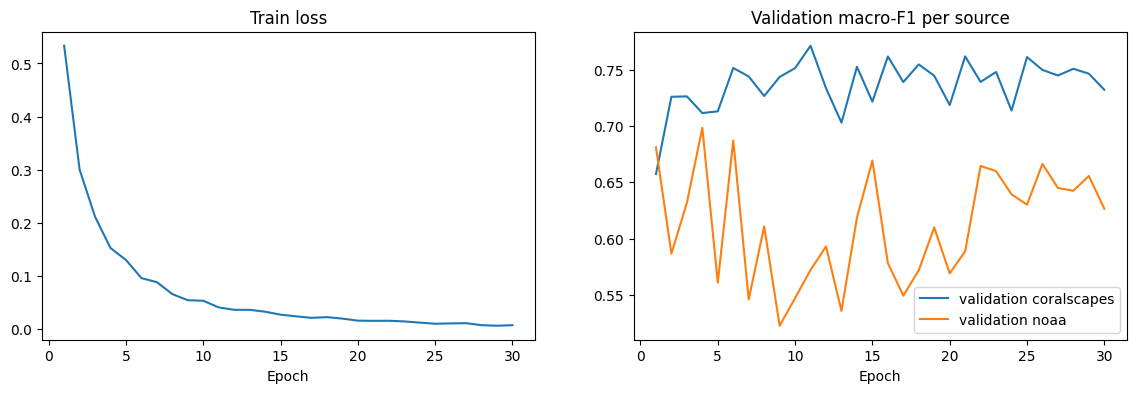

Best epoch for 'coralscapes': 11, macro-F1 0.7713
Best epoch, validation coralscapes: macro-F1 0.7713 over 3 classes present, recall: healthy 0.884, bleached 0.585, dead 0.773
Confusion matrix, validation coralscapes (rows true, columns predicted):
          healthy  bleached  dead
healthy      1270        17   150
bleached       39        62     5
dead          173         3   601
Best epoch, validation noaa: macro-F1 0.5721 over 2 classes present, recall: healthy 0.836, bleached 0.243, dead n/a
Confusion matrix, validation noaa (rows true, columns predicted):
          healthy  bleached  dead
healthy       813         8   152
bleached      360       143    86
dead            0         0     0


In [17]:
import matplotlib.pyplot as plt

epoch_numbers = [record["epoch"] for record in history]
per_source_f1 = {name: [scores(np.array(record["confusions"][name]))[3] for record in history]
                 for name in val_loaders}

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(epoch_numbers, [record["train_loss"] for record in history])
axes[0].set_title("Train loss")
axes[0].set_xlabel("Epoch")
for name, values in per_source_f1.items():
    axes[1].plot(epoch_numbers, values, label="validation " + name)
axes[1].set_title("Validation macro-F1 per source")
axes[1].set_xlabel("Epoch")
axes[1].legend()
plt.show()

best_record = max(history, key=lambda record: record["own_macro_f1"])
print("Best epoch for '{}': {}, macro-F1 {:.4f}".format(
    source, best_record["epoch"], best_record["own_macro_f1"]))
for name, matrix in best_record["confusions"].items():
    matrix = np.array(matrix)
    describe("Best epoch, validation " + name, matrix)
    print("Confusion matrix, validation {} (rows true, columns predicted):".format(name))
    print(pd.DataFrame(matrix, index=list(state_names.values()), columns=list(state_names.values())).to_string())

**Observation**: After one epoch, Coralscapes validation macro-F1 increased from 0.1341 to 0.6742, with bleached recall at 0.679 (72 of 106 patches). However, NOAA bleached recall was only 0.297 (175 of 589), so we still need more training and source comparisons before choosing the model.

**Observation:** After 30 epochs, we achieved the best Coralscapes validation macro-F1 of 0.7713 at epoch 11, compared to 0.1341 before training. Bleached recall was 0.585 (62 of 106 patches), while the final epoch dropped to 0.7321 macro-F1. Meanwhile, NOAA only reached 0.5721 macro-F1 at the selected checkpoint, showing weaker performance on the different dataset.